# Credit Risk Scorecard — German Credit Data

**Loan default prediction the way banks actually do it:** Weight-of-Evidence
binning, Information Value feature ranking, a logistic-regression scorecard
scaled to points (600 base, PDO 20), and validation with the metrics credit
teams report — ROC-AUC, Gini, KS, calibration — plus the cutoff tradeoff a
credit committee decides on.

Dataset: UCI Statlog German Credit — 1,000 applicants, 20 features,
30% bad (default) rate. Target: `default` = 1 for "bad" credit.

In [1]:
import sys
from pathlib import Path

# Make the repo root importable no matter where the notebook is run from.
for parent in [Path.cwd(), *Path.cwd().parents]:
    if (parent / "src").is_dir():
        sys.path.insert(0, str(parent))
        break

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

from src.data import CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, load_data
from src.evaluate import calibration_data, cutoff_tradeoff, model_metrics, roc_data
from src.scorecard import Scorecard
from src.train import derive_bands, make_logreg, make_xgboost

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80

df = load_data()
print(f"{len(df)} applicants, default rate {df['default'].mean():.1%}")
df.head()

1000 applicants, default rate 30.0%


,checking_status,duration_months,credit_history,purpose,credit_amount,savings_status,employment_since,installment_rate_pct,personal_status,other_debtors,...,property,age_years,other_installment_plans,housing,existing_credits_count,job,dependents_count,telephone,foreign_worker,default
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,0
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,1
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,0
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,0
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,1


## 1. Exploratory analysis

Defaults are 30% of the book — far too common for accuracy to mean
anything. What matters is *ranking* applicants by risk and *calibrating*
the probabilities.

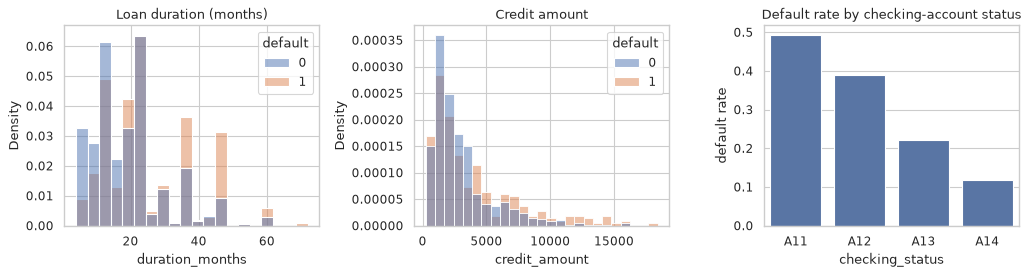

Checking status codes: A11 <0, A12 0-200, A13 >=200/salary, A14 no account
checking_status
A11    0.493
A12    0.390
A13    0.222
A14    0.117
Name: default, dtype: float64


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
sns.histplot(data=df, x="duration_months", hue="default", bins=20,
             stat="density", common_norm=False, ax=axes[0])
axes[0].set_title("Loan duration (months)")
sns.histplot(data=df, x="credit_amount", hue="default", bins=25,
             stat="density", common_norm=False, ax=axes[1])
axes[1].set_title("Credit amount")
bad_by_checking = df.groupby("checking_status")["default"].mean()
sns.barplot(x=bad_by_checking.index, y=bad_by_checking.values, ax=axes[2])
axes[2].set_title("Default rate by checking-account status")
axes[2].set_ylabel("default rate")
plt.tight_layout()
plt.show()

print("Checking status codes: A11 <0, A12 0-200, A13 >=200/salary, A14 no account")
print(bad_by_checking.round(3))

Applicants with an overdrawn checking account (A11) default at several
times the rate of those with no checking account (A14) — expect
`checking_status` to top the IV ranking.

## 2. WOE binning + Information Value

Each feature is binned (categories as-is, numerics by quantiles) and every
bin gets a Weight of Evidence: ln(share of goods / share of bads). IV sums
that signal per feature.

In [3]:
train_df, test_df = train_test_split(
    df, test_size=0.30, random_state=42, stratify=df["default"]
)
y_train, y_test = train_df["default"].to_numpy(), test_df["default"].to_numpy()

card = Scorecard(CATEGORICAL_FEATURES, NUMERIC_FEATURES).fit(train_df)
iv = card.iv_table
iv.head(10)

,feature,iv
0,checking_status,0.629996
1,duration_months,0.257502
2,credit_history,0.252002
3,savings_status,0.221311
4,property,0.138611
5,employment_since,0.138533
6,purpose,0.128992
7,other_installment_plans,0.117579
8,housing,0.102706
9,age_years,0.085624


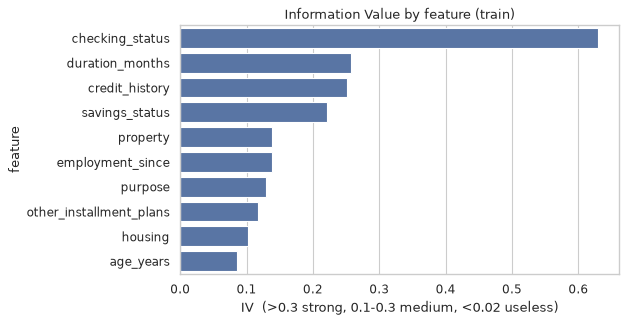

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(data=iv.head(10), x="iv", y="feature", ax=ax)
ax.set_title("Information Value by feature (train)")
ax.set_xlabel("IV  (>0.3 strong, 0.1-0.3 medium, <0.02 useless)")
plt.tight_layout()
plt.show()

## 3. Scorecard vs plain logistic regression vs XGBoost

The scorecard is the interpretable model. The other two answer the
question every model review asks: *what do we give up for that
interpretability?* (Spoiler: on 1,000 rows, essentially nothing.)

In [5]:
logreg = make_logreg().fit(train_df[FEATURES], y_train)
xgb = make_xgboost().fit(train_df[FEATURES], y_train)

probas = {
    "Scorecard (WOE + LR)": card.predict_default_proba(test_df),
    "Logistic regression": logreg.predict_proba(test_df[FEATURES])[:, 1],
    "XGBoost": xgb.predict_proba(test_df[FEATURES])[:, 1],
}
comparison = pd.DataFrame(
    {name: model_metrics(y_test, p) for name, p in probas.items()}
).T.rename(columns={"roc_auc": "ROC-AUC", "gini": "Gini", "ks": "KS"})
comparison.round(3)

,ROC-AUC,Gini,KS
Scorecard (WOE + LR),0.800,0.600,0.494
Logistic regression,0.801,0.602,0.494
XGBoost,0.796,0.592,0.459


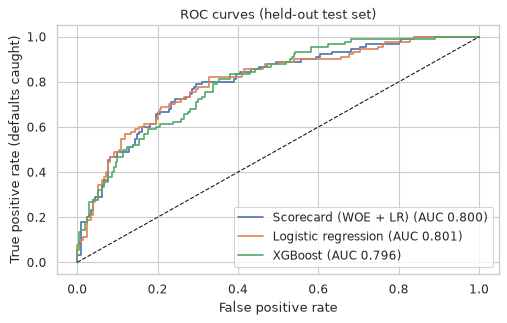

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for name, p in probas.items():
    roc = roc_data(y_test, p)
    ax.plot(roc["fpr"], roc["tpr"], label=f"{name} (AUC {model_metrics(y_test, p)['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (defaults caught)")
ax.set_title("ROC curves (held-out test set)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Calibration

A scorecard used for pricing and provisioning must not just rank — its
probabilities must mean something. Observed default rates track the
predicted PD closely across bands (slight under-prediction in the safest
band, where the observed rate is 0/30).

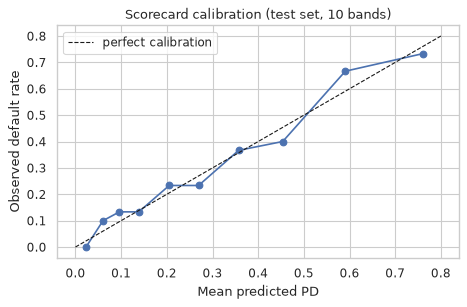

,count,mean_predicted_pd,observed_default_rate
0,30,0.023,0.000
1,30,0.060,0.100
2,30,0.096,0.133
3,30,0.139,0.133
4,30,0.205,0.233
5,30,0.270,0.233
6,30,0.357,0.367
7,30,0.454,0.400
8,30,0.591,0.667
9,30,0.761,0.733


In [7]:
cal = pd.DataFrame(calibration_data(y_test, probas["Scorecard (WOE + LR)"]))
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cal["mean_predicted_pd"], cal["observed_default_rate"], "o-")
ax.plot([0, 0.8], [0, 0.8], "k--", lw=1, label="perfect calibration")
ax.set_xlabel("Mean predicted PD")
ax.set_ylabel("Observed default rate")
ax.set_title("Scorecard calibration (test set, 10 bands)")
ax.legend()
plt.tight_layout()
plt.show()
cal.round(3)

## 5. Cutoff policy: approval rate vs bad rate

Decision bands are set on modelled PD — **approve if PD ≤ 15%, decline if
PD ≥ 50%**, review in between — and converted to score cutoffs through the
scorecard scaling (approve ≥ 537, decline < 487). The tradeoff table shows
what any other cutoff would buy or cost.

approve >= 537 | review 487-537 | decline < 487


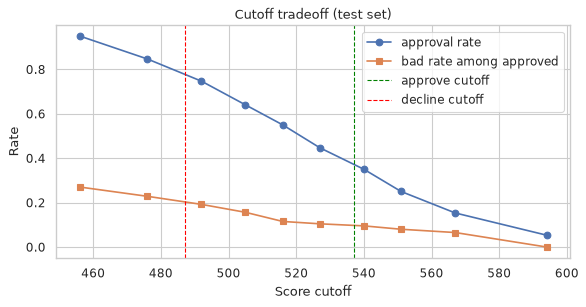

,cutoff,approval_rate,bad_rate_among_approved,share_of_bads_rejected
0,456.0,0.950,0.270,0.144
1,476.0,0.847,0.228,0.356
2,492.0,0.747,0.192,0.522
3,505.0,0.640,0.156,0.667
4,516.0,0.550,0.115,0.789
5,527.0,0.447,0.104,0.844
6,540.0,0.350,0.095,0.889
7,551.0,0.250,0.080,0.933
8,567.0,0.153,0.065,0.967
9,594.0,0.053,0.000,1.000


In [8]:
test_scores = card.score(test_df)
approve_cutoff, decline_cutoff = derive_bands(card)
print(f"approve >= {approve_cutoff:.0f} | review {decline_cutoff:.0f}-{approve_cutoff:.0f} | decline < {decline_cutoff:.0f}")

cutoffs = [round(float(c), 0) for c in np.quantile(test_scores, np.linspace(0.05, 0.95, 10))]
tradeoff = cutoff_tradeoff(y_test, test_scores, cutoffs)
fig, ax1 = plt.subplots(figsize=(7.5, 4))
ax1.plot(tradeoff["cutoff"], tradeoff["approval_rate"], "o-", label="approval rate")
ax1.plot(tradeoff["cutoff"], tradeoff["bad_rate_among_approved"], "s-", label="bad rate among approved")
ax1.axvline(approve_cutoff, color="green", ls="--", lw=1, label="approve cutoff")
ax1.axvline(decline_cutoff, color="red", ls="--", lw=1, label="decline cutoff")
ax1.set_xlabel("Score cutoff")
ax1.set_ylabel("Rate")
ax1.set_title("Cutoff tradeoff (test set)")
ax1.legend()
plt.tight_layout()
plt.show()
tradeoff.round(3)

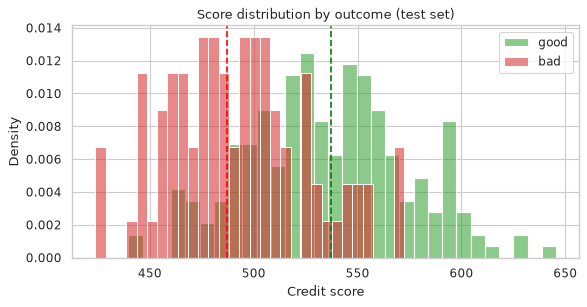

approve  n=109  bad rate 9.2%
review   n=128  bad rate 29.7%
decline  n= 63  bad rate 66.7%


In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4))
sns.histplot(x=test_scores[y_test == 0], bins=30, stat="density",
             label="good", color="tab:green", alpha=0.55, ax=ax)
sns.histplot(x=test_scores[y_test == 1], bins=30, stat="density",
             label="bad", color="tab:red", alpha=0.55, ax=ax)
ax.axvline(approve_cutoff, color="green", ls="--")
ax.axvline(decline_cutoff, color="red", ls="--")
ax.set_xlabel("Credit score")
ax.set_title("Score distribution by outcome (test set)")
ax.legend()
plt.tight_layout()
plt.show()

for band, mask in {
    "approve": test_scores >= approve_cutoff,
    "review": (test_scores >= decline_cutoff) & (test_scores < approve_cutoff),
    "decline": test_scores < decline_cutoff,
}.items():
    print(f"{band:8s} n={mask.sum():3d}  bad rate {y_test[mask].mean():.1%}")

## 6. Scoring one applicant — and explaining the decision

Because the score is a sum of per-feature points, any decision decomposes
into reason codes: the features where this applicant lost the most points
versus the best bin. That is exactly what an adverse-action notice needs.

In [10]:
from src.predict import score_applicant

bundle = {"scorecard": card, "approve_cutoff": approve_cutoff, "decline_cutoff": decline_cutoff}
applicant = {
    "checking_status": "A11", "duration_months": 36, "credit_history": "A34",
    "purpose": "A41", "credit_amount": 8200, "savings_status": "A65",
    "employment_since": "A72", "installment_rate_pct": 4,
    "personal_status": "A93", "other_debtors": "A101",
    "residence_since_years": 1, "property": "A124", "age_years": 24,
    "other_installment_plans": "A141", "housing": "A151",
    "existing_credits_count": 2, "job": "A172", "dependents_count": 1,
    "telephone": "A191", "foreign_worker": "A201",
}
result = score_applicant(applicant, bundle=bundle)
print(f"Score {result['credit_score']}  ->  {result['band'].upper()}  (PD {result['default_probability']:.1%})")
print("Reason codes:")
for reason in result["reason_codes"]:
    print(" -", reason)

Score 461  ->  DECLINE  (PD 71.1%)
Reason codes:
 - Loan duration: 36
 - Checking account status: checking account balance < 0
 - Foreign worker status: foreign worker
 - Employment stability: employed < 1 year


## Takeaways & limitations

- The interpretable scorecard **matches** plain logistic regression and
  XGBoost on AUC/KS here — on small tabular lending data, WOE + LR is
  hard to beat, and it ships with explanations built in.
- `checking_status` alone carries IV 0.63 — by far the strongest feature,
  ahead of loan duration and credit history.
- **Fair-lending caveat:** this 1970s–90s-era dataset contains protected
  attributes (sex/marital status in `personal_status`, `foreign_worker`,
  `age_years`). They are kept here to reproduce the classic benchmark
  faithfully — a production scorecard under ECOA-style rules would
  exclude them and document the performance delta.
- 1,000 rows is tiny: treat the exact metrics as indicative, refit on
  current portfolio data, and monitor calibration drift over time.